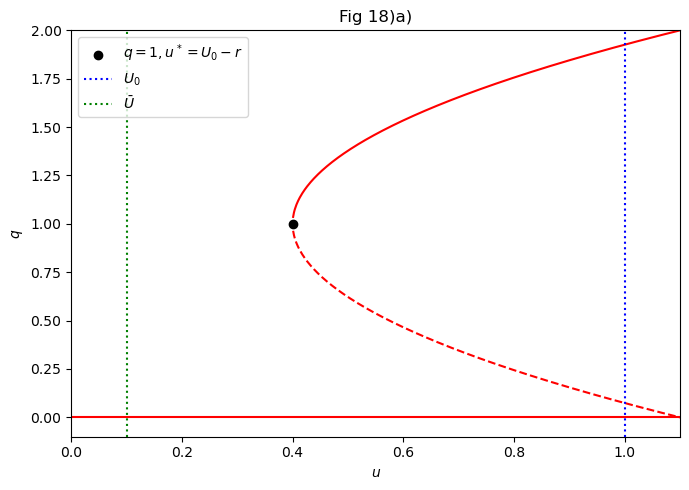

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

zeta = 0.8
D = 1
delta = 0.1
e_1 = 0.1
e_2 = 0.2
sigma = 0.5
U_dash, U_0 = 0.1, 1

r_nullcline = 0.6
u_star = U_0 - r_nullcline

# Plotting Nullclines
def q_nullcline_fn(u, r):
    arg = (r + u - U_0) / (r + delta)

    sqrt = np.sqrt(np.maximum(arg, 0))

    q_upper = 1 + sqrt
    q_lower = 1 - sqrt

    # Only plot where the square root is physically defined
    q_upper = np.where(arg >= 0, q_upper, np.nan)
    q_lower = np.where(arg >= 0, q_lower, np.nan)

    return q_upper, q_lower

def u_nullcline_fn(u):
    q_u = (e_1 * (U_0 - u)) / (e_2 * (u - U_dash))
    return np.where(q_u >= 0, q_u, np.nan)

u_values = np.linspace(0, 1.5, 1000)

q_upper, q_lower = q_nullcline_fn(u_values, r_nullcline)
q_laminar = np.full_like(u_values, 0)
u_nullcline = u_nullcline_fn(u_values)

# Plotting the q-nullclines
plt.figure(figsize=(7, 5))
plt.plot(u_values, q_upper, color='red')
plt.plot(u_values, q_lower, color='red', linestyle='--')   
plt.plot(u_values, q_laminar, color='red')
plt.scatter(u_star, 1, label=r"$q=1, u^*=U_0 - r$", color='black')
plt.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
plt.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
plt.xlabel(r'$u$')
plt.ylabel(r'$q$')
plt.xlim(U_dash - 0.1, U_0 + 0.1)
plt.ylim(-0.1, 2)
plt.title('Fig 18)a)')
plt.legend()
plt.tight_layout()    
plt.show()


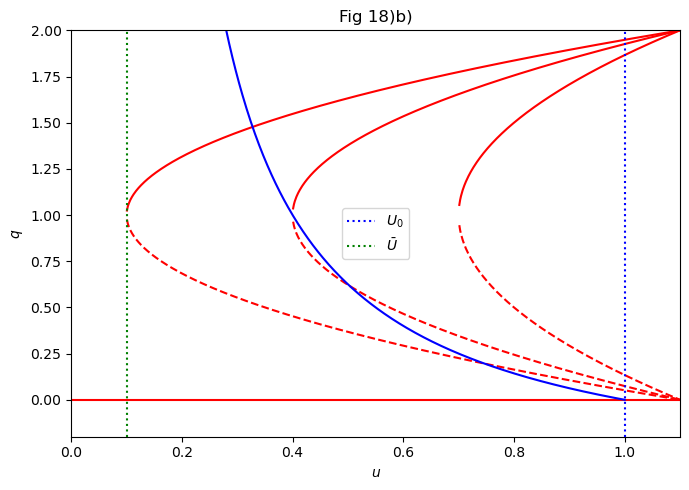

In [105]:
r=[0.3, 0.6, 0.9]

plt.figure(figsize=(7, 5))
plt.title('Fig 18)b)')
for _ in r:
    q_upper, q_lower = q_nullcline_fn(u_values, _)
    plt.plot(u_values, q_upper, color='red')
    plt.plot(u_values, q_lower, linestyle='--', color='red')
        
plt.plot(u_values, q_laminar, color='red')
plt.plot(u_values, u_nullcline, color='blue')

plt.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
plt.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
plt.xlim(U_dash - 0.1, U_0 + 0.1)
plt.ylim(-0.2, 2)
plt.xlabel(r'$u$')
plt.ylabel(r'$q$')
plt.legend()
plt.tight_layout()    
plt.show()

In [109]:
def system_ode(t, y, r):
    q, u = y
    dqdt = q * (r + (u - U_0) - (r + delta) * (q - 1)**2)
    dudt = e_1 * (U_0 - u) + e_2 * (U_dash - u) * q
    return [dqdt, dudt]

init_state = [0.15, 0.98]  # [q_0, u_0]
t_span = (0, 100)
t_eval = np.linspace(0, 100, 2000)

sol_excitable = solve_ivp(system_ode, t_span, init_state, args=(r[1],), t_eval=t_eval)
q_traj_excitable, u_traj_excitable = sol_excitable.y[0], sol_excitable.y[1]

sol_bistable = solve_ivp(system_ode, t_span, init_state, args=(r[2],), t_eval=t_eval)
q_traj_bistable, u_traj_bistable = sol_bistable.y[0], sol_bistable.y[1]

0.6


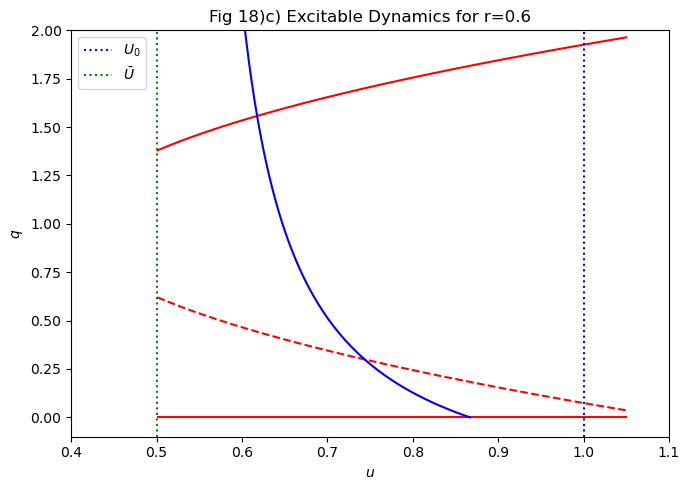

0.9


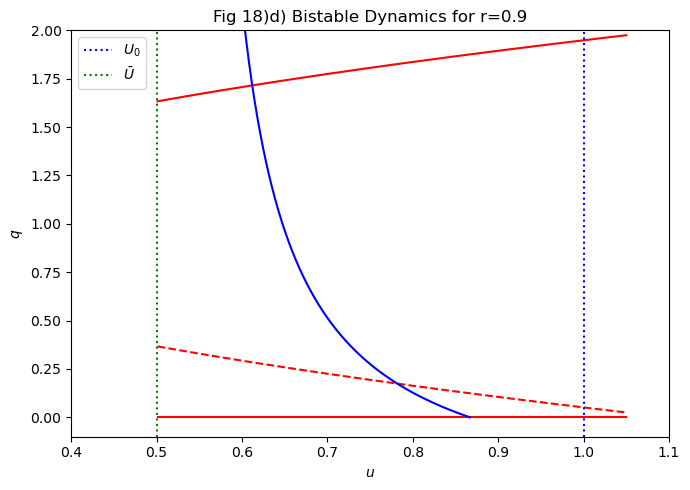

In [112]:
#Excitable Dynamics for r=0.6
q_upper, q_lower = q_nullcline_fn(u_values, r[1])
print(r[1]) 

plt.figure(figsize=(7, 5))
plt.plot(u_values, q_upper, color='red')
plt.plot(u_values, q_lower, color='red', linestyle='--')   
plt.plot(u_values, q_laminar, color='red')
plt.plot(u_values, u_nullcline, color='blue')
#plt.plot(u_traj_excitable, q_traj_excitable, color='black')
plt.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
plt.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
plt.xlabel(r'$u$')
plt.ylabel(r'$q$')
plt.xlim(U_dash - 0.1, U_0 + 0.1)
plt.ylim(-0.1, 2)
plt.title('Fig 18)c) Excitable Dynamics for r=0.6')
plt.legend()
plt.tight_layout()    
plt.show()

#Bistable Dynamics for r=0.9
q_upper, q_lower = q_nullcline_fn(u_values, r[2])
print(r[2])

plt.figure(figsize=(7, 5))
plt.plot(u_values, q_upper, color='red')
plt.plot(u_values, q_lower, color='red', linestyle='--')   
plt.plot(u_values, q_laminar, color='red')
plt.plot(u_values, u_nullcline, color='blue')
#plt.plot(u_traj_bistable, q_traj_bistable, color='black')
plt.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
plt.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
plt.xlabel(r'$u$')
plt.ylabel(r'$q$')
plt.xlim(U_dash - 0.1, U_0 + 0.1)
plt.ylim(-0.1, 2)
plt.title('Fig 18)d) Bistable Dynamics for r=0.9')
plt.legend()
plt.tight_layout()    
plt.show()